# Initialization

Run the following code to import the modules you'll need. After your finish the assignment, **remember to run all cells** and save the note book to your local machine as a PDF for gradescope submission.

In [1]:
import time
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Download data

In this section we will download the data and setup the paths.


In [2]:
# Download the data
if not os.path.exists('/content/aerialseq.npy'):
    !wget https://www.cs.cmu.edu/~deva/data/aerialseq.npy -O /content/aerialseq.npy
if not os.path.exists('/content/antseq.npy'):
    !wget https://www.cs.cmu.edu/~deva/data/antseq.npy -O /content/antseq.npy

--2026-10-02 20:03:06--  https://www.cs.cmu.edu/~deva/data/aerialseq.npy
Resolving www.cs.cmu.edu (www.cs.cmu.edu)... 128.2.42.95
Connecting to www.cs.cmu.edu (www.cs.cmu.edu)|128.2.42.95|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 92160128 (88M)
Saving to: ‘/content/aerialseq.npy’

/content/aerialseq. 100%[===================>]  87.89M  1.82MB/s    in 49s     

2026-10-02 20:03:57 (1.79 MB/s) - ‘/content/aerialseq.npy’ saved [92160128/92160128]

--2026-10-02 20:03:57--  https://www.cs.cmu.edu/~deva/data/antseq.npy
Resolving www.cs.cmu.edu (www.cs.cmu.edu)... 128.2.42.95
Connecting to www.cs.cmu.edu (www.cs.cmu.edu)|128.2.42.95|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 65536128 (62M)
Saving to: ‘/content/antseq.npy’

/content/antseq.npy 100%[===================>]  62.50M  1.87MB/s    in 34s     

2026-10-02 20:04:31 (1.83 MB/s) - ‘/content/antseq.npy’ saved [65536128/65536128]



# Q3: Affine Motion Subtraction

## Q3.1: Dominant Motion Estimation (15 points)

In [3]:
from scipy.interpolate import RectBivariateSpline
from numpy.linalg import lstsq

def LucasKanadeAffine(It, It1, threshold, num_iters):
    """
    :param It        : (H, W), current image
    :param It1       : (H, W), next image
    :param threshold : (float), if the length of dp < threshold, terminate the optimization
    :param num_iters : (int), number of iterations for running the optimization

    :return: M       : (2, 3) The affine transform matrix
    """
    # Initial M
    M = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]])

    # ===== your code here! =====
    H, W = It.shape
    y_img = np.arange(H)
    x_img = np.arange(W)
    spline_It1 = RectBivariateSpline(y_img, x_img, It1)
    x = np.arange(W)
    y = np.arange(H)
    x_grid, y_grid = np.meshgrid(x, y)
    for itr in range(num_iters):
      x_warped = (M[0, 0] * x_grid + M[0, 1] * y_grid + M[0, 2])
      y_warped = (M[1, 0] * x_grid + M[1, 1] * y_grid + M[1, 2])

      valid = ((x_warped >= 0) & (x_warped <= W - 1) & (y_warped >= 0) & (y_warped <= H - 1))

      xv = x_grid[valid]
      yv = y_grid[valid]

      xw = x_warped[valid]
      yw = y_warped[valid]

      warped_It1 = spline_It1.ev(yw, xw)

      Ix = spline_It1.ev(yw, xw, dx=0, dy=1)
      Iy = spline_It1.ev(yw, xw, dx=1, dy=0)

      A1 = (Ix * xv).reshape(-1, 1)
      A2 = (Ix * yv).reshape(-1, 1)
      A3 = Ix.reshape(-1, 1)

      A4 = (Iy * xv).reshape(-1, 1)
      A5 = (Iy * yv).reshape(-1, 1)
      A6 = Iy.reshape(-1, 1)

      A = np.hstack((A1, A2, A3, A4, A5, A6))

      b = (It[valid] - warped_It1).reshape(-1, 1)


      delta_p = lstsq(A, b, rcond=None)[0].flatten()

      delta_M = np.array([[delta_p[0], delta_p[1], delta_p[2]], [delta_p[3], delta_p[4], delta_p[5]]])

      M += delta_M

      if np.linalg.norm(delta_p) < threshold:
          break


    # ===== End of code =====
    return M

## Debug Q3.1



Feel free to use and modify the following snippet to debug your implementation. The snippet simply visualizes the translation resulting from running LK on a single frame. When you warp the source frame using the obtained transformation matrix, it should resemble the target frame.

Text(0.5, 1.0, 'Warped Source image')

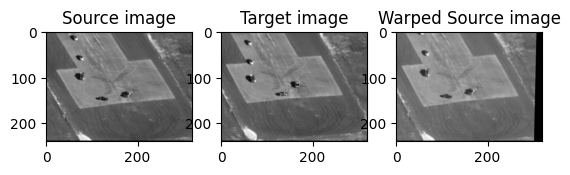

In [4]:
import cv2

num_iters = 100
threshold = 0.01
seq = np.load("/content/aerialseq.npy")
It = seq[:,:,0]
It1 = seq[:,:,10]

# Source frame
plt.figure()
plt.subplot(1,3,1)
plt.imshow(It, cmap='gray')
plt.title('Source image')

# Target frame
plt.subplot(1,3,2)
plt.imshow(It1, cmap='gray')
plt.title('Target image')

# Warped source frame
M = LucasKanadeAffine(It, It1, threshold, num_iters)
warped_It = cv2.warpAffine(It, M,(It.shape[1],It.shape[0]))
plt.subplot(1,3,3)
plt.imshow(warped_It, cmap='gray')
plt.title('Warped Source image')

# Q3.2: Moving Object Detection (10 points)

In [5]:
import numpy as np
from scipy.ndimage import binary_erosion
from scipy.ndimage import binary_dilation
from scipy.ndimage import affine_transform
import scipy.ndimage
import cv2

def SubtractDominantMotion(It, It1, num_iters, threshold, tolerance):
    """
    :param It        : (H, W), current image
    :param It1       : (H, W), next image
    :param num_iters : (int), number of iterations for running the optimization
    :param threshold : (float), if the length of dp < threshold, terminate the optimization
    :param tolerance : (float), binary threshold of intensity difference when computing the mask
    :return: mask    : (H, W), the mask of the moved object
    """
    mask = np.ones(It.shape, dtype=bool)

    # ===== your code here! =====
    M = LucasKanadeAffine(It, It1, threshold, num_iters)
    warped_It = cv2.warpAffine(It,M,(It.shape[1], It.shape[0]))
    mask = np.abs(It1 - warped_It) > tolerance
    mask = binary_erosion(mask)
    mask = binary_dilation(mask)
    # ===== End of code =====

    return mask


## Q3.3: Tracking with affine motion (10 points)

In [6]:
from tqdm import tqdm

def TrackSequenceAffineMotion(seq, num_iters, threshold, tolerance):
    """
    :param seq       : (H, W, T), sequence of frames
    :param num_iters : int, number of iterations for running the optimization
    :param threshold : float, if the length of dp < threshold, terminate the optimization
    :param tolerance : (float), binary threshold of intensity difference when computing the mask
    :return: masks   : (T, 4) moved objects for each frame
    """
    H, W, N = seq.shape

    masks =[]
    It = seq[:,:,0]

    # ===== your code here! =====
    for i in tqdm(range(1, seq.shape[2])):
        It1 = seq[:, :, i]
        mask = SubtractDominantMotion(It, It1, num_iters, threshold, tolerance)
        masks.append(mask)
        It = It1

    # ===== End of code =====
    masks = np.stack(masks, axis=2)
    return masks

## Q3.3 (a) - Track Ant Sequence

In [7]:
seq = np.load("/content/antseq.npy")

# NOTE: feel free to play with these parameters
num_iters = 1000
threshold = 0.01
tolerance = 0.2

tic = time.time()
masks = TrackSequenceAffineMotion(seq, num_iters, threshold, tolerance)
toc = time.time()
print('\nAnt Sequence takes %f seconds' % (toc - tic))

100%|██████████| 124/124 [01:20<00:00,  1.54it/s]


Ant Sequence takes 80.830932 seconds


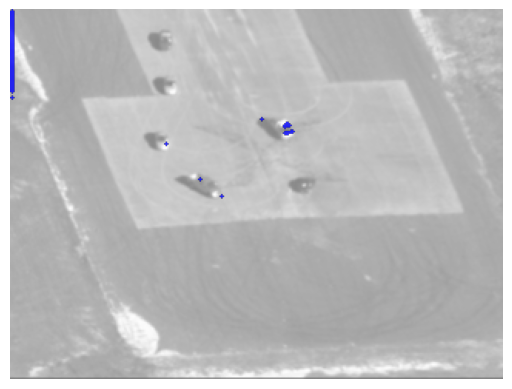

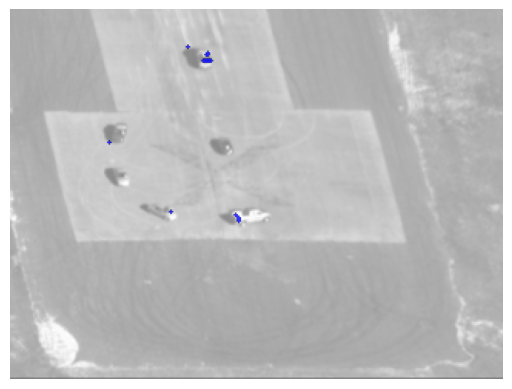

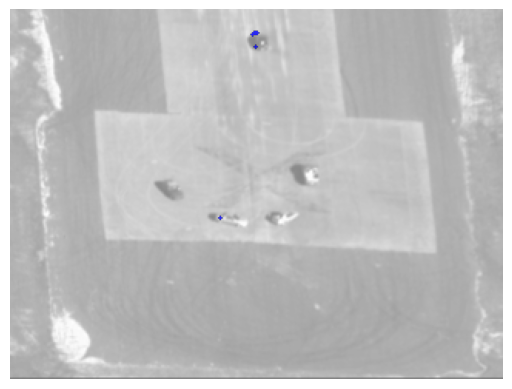

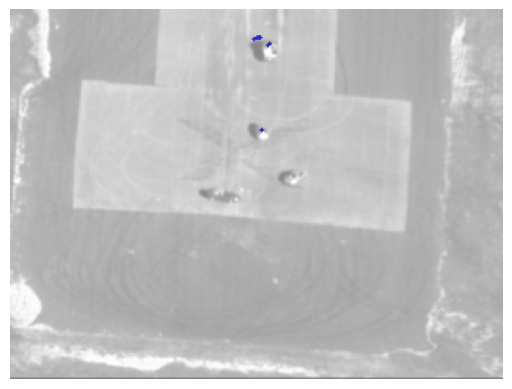

In [9]:
frames_to_save = [29, 59, 89, 119]

# TODO: visualize
for idx in frames_to_save:
    frame = seq[:, :, idx]
    mask = masks[:, :, idx]

    plt.figure()
    plt.imshow(frame, cmap="gray", alpha=0.5)
    plt.imshow(np.ma.masked_where(np.invert(mask), mask), cmap='winter', alpha=0.8)
    plt.axis('off')


### Q3.3 (b) - Track Aerial Sequence

In [8]:
seq = np.load("/content/aerialseq.npy")

# NOTE: feel free to play with these parameters
num_iters = 1000
threshold = 0.01
tolerance = 0.2

tic = time.time()
masks = TrackSequenceAffineMotion(seq, num_iters, threshold, tolerance)
toc = time.time()
print('\nAnt Sequence takes %f seconds' % (toc - tic))

100%|██████████| 149/149 [02:57<00:00,  1.19s/it]


Ant Sequence takes 177.160524 seconds


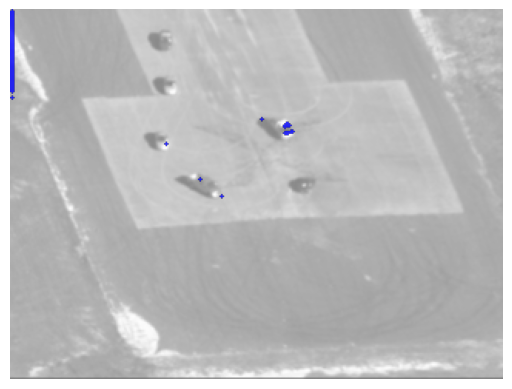

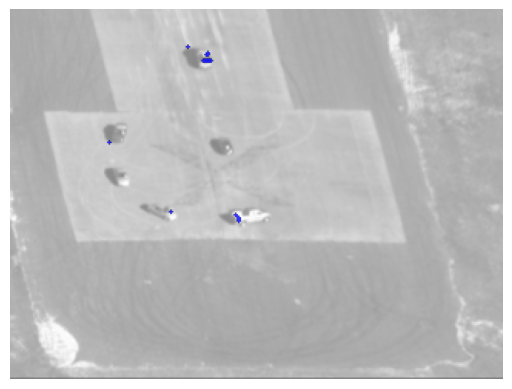

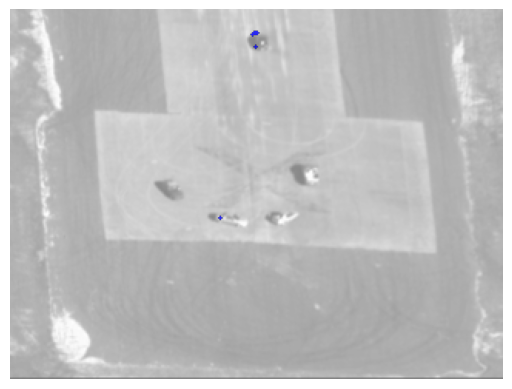

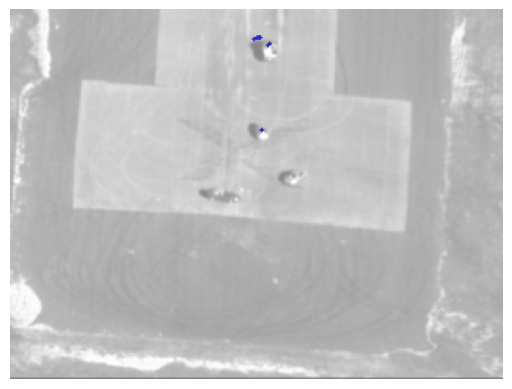

In [10]:
frames_to_save = [29, 59, 89, 119]

# TODO: visualize
for idx in frames_to_save:
    frame = seq[:, :, idx]
    mask = masks[:, :, idx]

    plt.figure()
    plt.imshow(frame, cmap="gray", alpha=0.5)
    plt.imshow(np.ma.masked_where(np.invert(mask), mask), cmap='winter', alpha=0.8)
    plt.axis('off')